# Early AstroMiNN acquisition → later FLARE energy

**Question:** do objects with high early classification uncertainty also receive high anomaly energy once their light curves develop?

This is a retrospective, paired-object comparison, not an AL retraining experiment. It uses the existing January 2025 BOOM/ZTF pool: one frozen early snapshot per object, with historical-training overlap and known-SSO exclusions inherited from the pool construction. The original query was capped at 5,000 alerts; this is not a complete January census.

1. Preserve the early pool. Rank **all** its objects by AstroMiNN entropy and freeze a top-25 acquisition.
2. Reconstruct photometry available at the early snapshot and at **snapshot + 60 days**.
3. Apply FLARE's native first-100-day representation and quality gate.
4. Compare early entropy with later FLARE `bts6.anomaly_energy`, including nonselected objects.

**Start with `RUN_MODE = "coverage"`**. This retrieves/caches photometry and reports feasibility without loading either classifier. Then change only `RUN_MODE` to `"compare"` and run all cells again. Existing January AstroMiNN predictions are reused if their IDs, alert indices and pool metadata match. No retraining or label-provider queries are performed.

**Interpretation:** high energy does not establish an outside-taxonomy label; entropy measures classification uncertainty. Missing FLARE eligibility remains a reported outcome, not a reason to select replacement AL objects. The default FLARE scores use photometry with external context explicitly missing, as supported by FLARE; they are not a reproduction of its full-context paper results.


## 1. Delta setup and paths

Place this notebook in `active-learning/notebooks/presentation/` and use the `al-pipeline` kernel. Both passes can use CPUs when the existing January inference cache is present. A starting allocation is **4 CPUs, 16 GB RAM, 1 hour**; actual time depends on BOOM response times and cache coverage. Save the executed notebook before returning the review archive.

The `al-pipeline` environment must also have the FLARE clone's dependencies. If FLARE has not been installed there, run `python -m pip install -e /path/to/flare` in that environment. This notebook does not install packages or change your environment automatically. Export `BABAMUL_API_TOKEN` in the process that starts the kernel; it is never written into outputs or caches.

The paths below are deliberately Delta-specific. Existing pools and old inference products are read only. Set `POOL_DIR` or `FLARE_REPO` explicitly if detection chooses the wrong clone. Use a new `RUN_ID` when changing the experiment settings or source data.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import gzip, hashlib, inspect, json, os, subprocess, sys, tarfile
import warnings

CPU_THREADS = max(1, int(os.environ.get("SLURM_CPUS_PER_TASK", "4")))
os.environ["OMP_NUM_THREADS"] = str(CPU_THREADS)
os.environ["OPENBLAS_NUM_THREADS"] = str(CPU_THREADS)
os.environ["MKL_NUM_THREADS"] = str(CPU_THREADS)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
try:
    from IPython.display import display
except ImportError:
    display = print

WORKSPACE = Path("/projects/bcrv/dkourtesis/applecider-al-workspace")
AL_REPO = WORKSPACE / "active-learning"
PERSISTENT_ROOT = Path("/projects/bcrv/dkourtesis/applecider_adaptive")
POOL_ID = "boom_ztf_2025_january_early10_v1"
RUN_ID = "early_astrominn_later_flare_january_v1"
RUN_MODE = "coverage"                   # "coverage" first; "compare" second
FOLLOWUP_DAYS = 60.0
ACQUISITION_BUDGET = 25
FLARE_SCHEME = "bts6"
MODEL_NAME = "astrominn_vit135"
MODEL_CLASSES = ("SN I", "SN II", "CV", "AGN", "TDE")
QUERY_BATCH_SIZE = 50
ALERT_QUERY_LIMIT = 20000              # hitting the cap triggers batch splitting
INFERENCE_BATCH_SIZE = 64
DEVICE = "cpu"                        # use "cuda" only inside a GPU allocation
ALLOW_NEW_INFERENCE = False            # cache absence produces a clear stop
MIN_PAIRED_FOR_SUMMARY = 30             # presentation caution, not an eligibility cut

def first_existing(paths, required_child=None):
    for path in paths:
        if (path / required_child).exists() if required_child else path.exists():
            return path
    raise FileNotFoundError("None of these paths exists: " + ", ".join(map(str, paths)))

POOL_DIR = first_existing([
    Path("/work/nvme/bcrv/dkourtesis/applecider_adaptive/pools") / POOL_ID,
    Path("/work/hdd/bcrv/dkourtesis/applecider_adaptive/pools") / POOL_ID,
    PERSISTENT_ROOT / "pools" / POOL_ID,
], "candidate_pool.csv")
FLARE_REPO = first_existing([
    WORKSPACE / "flare", WORKSPACE / "applecider-flare",
    Path.home() / "external/applecider-flare",
], "flare/fetch.py")
LEGACY_INFERENCE = PERSISTENT_ROOT / "runs/plan1_boom_2025_january_resolver_v1/object_inference.npz"
REPORT_DIR = PERSISTENT_ROOT / "reports" / RUN_ID
RAW_CACHE_DIR = POOL_DIR.parent.parent / "comparisons" / RUN_ID / "raw_boom"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
RAW_CACHE_DIR.mkdir(parents=True, exist_ok=True)

if RUN_MODE not in {"coverage", "compare"}:
    raise ValueError("RUN_MODE must be coverage or compare")
if FOLLOWUP_DAYS <= 0 or ACQUISITION_BUDGET <= 0:
    raise ValueError("Follow-up and acquisition budget must be positive")
if AL_REPO.is_dir():
    sys.path.insert(0, str(AL_REPO / "src"))
sys.path.insert(0, str(FLARE_REPO))
try:
    import flare
    from flare import data as flare_data
    from flare.fetch import to_events
    from flare.features import extract_from_array
    from flare.config import resolve_scheme
    from al_pipeline.astronomy.boom.client import BoomClient
    from al_pipeline.core.types import ClassificationPredictions
    from al_pipeline.core.scoring.entropy import EntropyScorer
except ImportError as exc:
    raise ImportError("Use al-pipeline with FLARE installed from the configured clone. "
                      "Missing dependency: " + str(exc)) from exc

if not Path(flare.__file__).resolve().is_relative_to(FLARE_REPO.resolve()):
    raise RuntimeError("Kernel already imported a different FLARE clone; restart it")
plt.rcParams.update({"font.family": "serif", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "savefig.bbox": "tight"})
print("Mode:", RUN_MODE, "| follow-up:", FOLLOWUP_DAYS, "days")
print("Pool:", POOL_DIR)
print("FLARE:", FLARE_REPO, "| version:", getattr(flare, "__version__", "unknown"))
print("Existing inference:", LEGACY_INFERENCE.exists())
print("Reports:", REPORT_DIR)


Mode: coverage | follow-up: 60.0 days
Pool: /work/hdd/bcrv/dkourtesis/applecider_adaptive/pools/boom_ztf_2025_january_early10_v1
FLARE: /projects/bcrv/dkourtesis/applecider-al-workspace/flare | version: 2.0.0
Existing inference: True
Reports: /projects/bcrv/dkourtesis/applecider_adaptive/reports/early_astrominn_later_flare_january_v1


## 2. Freeze the one-object, one-snapshot universe

The January pool already contains one sample per object. This notebook deliberately stops if that assumption is false: silently aggregating repeated snapshots would change the experiment. Acquisition time is the saved packet JD, not the time we query BOOM today.

Hashes protect cache reuse. Original alert construction is inherited from the saved pool; this is a historical reconstruction of measurements, not proof that every retained AUX measurement was delivered to the broker by the exact historical wall-clock time.


In [2]:
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def write_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + "\n")
    temporary.replace(path)

def git_revision(path):
    result = subprocess.run(["git", "-C", str(path), "rev-parse", "HEAD"],
                            capture_output=True, text=True)
    return result.stdout.strip() if result.returncode == 0 else None

manifest_path = POOL_DIR / "candidate_pool.csv"
source_path = POOL_DIR / "source_index.json"
manifest = pd.read_csv(manifest_path, dtype={"object_id": str, "source_reference": str})
source_records = json.loads(source_path.read_text())
for row in source_records:
    if not isinstance(row["candid"], (int, str)) or isinstance(row["candid"], bool):
        raise TypeError("Candid must be an exact integer/string, never a rounded float")
    row["candid"] = str(row["candid"])
source = pd.DataFrame(source_records)
source["object_id"] = source["object_id"].astype(str)
if set(manifest.pool_id.astype(str)) != {POOL_ID}:
    raise RuntimeError("Manifest pool_id does not match configuration")
if manifest.object_id.duplicated().any() or source.object_id.duplicated().any():
    raise RuntimeError("Expected one early snapshot per object; prepare a dedicated snapshot pool")
if set(manifest.object_id) != set(source.object_id):
    raise RuntimeError("Manifest and source index do not contain the same objects")
early = source.merge(manifest[["object_id", "alert", "source_reference", "filepath"]],
                     on=["object_id", "alert", "source_reference"],
                     how="left", validate="one_to_one")
if early.filepath.isna().any():
    raise RuntimeError("Source snapshots do not match the manifest")
early["jd"] = pd.to_numeric(early.jd, errors="raise")
if not np.isfinite(early.jd).all() or not early.alert.between(0, 10).all():
    raise RuntimeError("Expected finite acquisition times and alert indices <= 10")
if not early.jd.between(2460676.5, 2460707.5, inclusive="left").all():
    raise RuntimeError("Default pool must contain January 2025 snapshots")
if len(early) < ACQUISITION_BUDGET:
    raise RuntimeError("Acquisition budget exceeds the early pool")
early = early.sort_values("object_id", kind="stable").reset_index(drop=True)
early["late_cutoff_jd"] = early.jd + FOLLOWUP_DAYS
early.to_csv(REPORT_DIR / "early_snapshots.csv", index=False)

scheme = resolve_scheme(FLARE_SCHEME)
config = {
    "schema_version": 1, "pool_id": POOL_ID, "pool_dir": str(POOL_DIR),
    "manifest_sha256": sha256(manifest_path), "source_index_sha256": sha256(source_path),
    "followup_days": FOLLOWUP_DAYS, "budget": ACQUISITION_BUDGET,
    "snapshot_policy": "one_saved_snapshot_per_object",
    "astro_model": MODEL_NAME, "astro_classes": list(MODEL_CLASSES),
    "flare_scheme": FLARE_SCHEME, "flare_horizon_days": float(scheme.horizon_days),
    "flare_version": getattr(flare, "__version__", None),
    "flare_revision": git_revision(FLARE_REPO), "al_revision": git_revision(AL_REPO),
    "flare_context_policy": "all_external_context_missing_NaN",
    "to_events_sha256": hashlib.sha256(inspect.getsource(to_events).encode()).hexdigest(),
    "quality_sha256": hashlib.sha256(inspect.getsource(flare_data.passes_quality).encode()).hexdigest(),
    "features_sha256": sha256(Path(inspect.getfile(extract_from_array))),
    "quality_defaults": {name: getattr(flare_data, name) for name in
        ["MIN_OBS_TOTAL", "MIN_OBS_G", "MIN_OBS_R", "MIN_OBS_I", "MIN_BANDS_OBSERVED"]},
    "color_window_days": float(flare_data.COLOR_WINDOW_DAYS),
    "raw_query_batch_size": QUERY_BATCH_SIZE,
    "raw_alert_query_limit": ALERT_QUERY_LIMIT,
}
for name in ("ingestion_report.json", "source_config.json"):
    if (POOL_DIR / name).exists():
        config[name + "_sha256"] = sha256(POOL_DIR / name)
config_path = REPORT_DIR / "run_config.json"
if config_path.exists() and json.loads(config_path.read_text()) != config:
    raise RuntimeError("RUN_ID already has different settings/input hashes. Choose a new RUN_ID")
write_json(config_path, config)
config_hash = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()
print("Early objects:", len(early), "| actual snapshot interval JD:", early.jd.min(), early.jd.max())
display(early[["object_id", "alert", "jd", "late_cutoff_jd"]].head())


Early objects: 2725 | actual snapshot interval JD: 2460707.0621528 2460707.0747454


,object_id,alert,jd,late_cutoff_jd
0,ZTF18aauetra,2,2.460707e+06,2.460767e+06
1,ZTF18aavqspn,10,2.460707e+06,2.460767e+06
2,ZTF18aawagor,9,2.460707e+06,2.460767e+06
3,ZTF18aaxaurk,1,2.460707e+06,2.460767e+06
4,ZTF18aaxpluc,4,2.460707e+06,2.460767e+06


## 3. Retrieve and cache photometry for the full early universe

We query **AUX history plus triggered alerts**, not AUX alone. This avoids interpreting an incomplete AUX history as a physical lack of follow-up. Query batches are saved as compressed raw JSON with their retrieval date. Subsequent runs reuse them without a token.

Triggered-alert queries are bounded by the latest required follow-up cutoff, then each object's measurements are filtered by its own cutoff. Capped responses are split and retried; an unresolvable cap stops the run. API failures also stop rather than becoming quality failures. No cutouts or catalog labels are requested.


In [3]:
def fetch_alerts_without_truncation(client, object_ids, max_jd):
    rows = client.find(catalog_name="ZTF_alerts",
        filter_document={"objectId": {"$in": object_ids}, "candidate.jd": {"$lte": max_jd}},
        limit=ALERT_QUERY_LIMIT,
        projection={"_id": 1, "objectId": 1, "candidate.jd": 1, "candidate.fid": 1,
                    "candidate.magpsf": 1, "candidate.sigmapsf": 1,
                    "candidate.issdiffpos": 1})
    if len(rows) < ALERT_QUERY_LIMIT:
        return rows
    if len(object_ids) == 1:
        raise RuntimeError("Alert cap reached for " + object_ids[0] + "; increase cap with a new RUN_ID")
    midpoint = len(object_ids) // 2
    return (fetch_alerts_without_truncation(client, object_ids[:midpoint], max_jd)
            + fetch_alerts_without_truncation(client, object_ids[midpoint:], max_jd))

aux_by_object, alerts_by_object, raw_receipts = {}, {}, []
client = None
ids = early.object_id.tolist()
for start in range(0, len(ids), QUERY_BATCH_SIZE):
    batch_ids = ids[start:start + QUERY_BATCH_SIZE]
    max_jd = float(early.loc[early.object_id.isin(batch_ids), "late_cutoff_jd"].max())
    cache_path = RAW_CACHE_DIR / f"batch_{start:06d}.json.gz"
    if cache_path.exists():
        with gzip.open(cache_path, "rt") as handle:
            payload = json.load(handle)
        if payload["config_hash"] != config_hash or payload["object_ids"] != batch_ids:
            raise RuntimeError("Raw cache belongs to different settings or IDs: " + str(cache_path))
    else:
        if client is None:
            client = BoomClient(query_batch_size=QUERY_BATCH_SIZE)
        aux = client.find_by_ids(catalog_name="ZTF_alerts_aux", ids=batch_ids,
                                 projection={"_id": 1, "prv_candidates": 1})
        alerts = fetch_alerts_without_truncation(client, batch_ids, max_jd)
        payload = {"config_hash": config_hash, "object_ids": batch_ids,
                   "retrieved_utc": datetime.now(timezone.utc).isoformat(),
                   "max_query_jd": max_jd, "aux": aux, "alerts": alerts}
        temporary = cache_path.with_name(cache_path.name + ".tmp")
        with gzip.open(temporary, "wt") as handle:
            json.dump(payload, handle, allow_nan=False)
        temporary.replace(cache_path)
    for doc in payload["aux"]:
        oid = str(doc["_id"])
        if oid not in batch_ids or oid in aux_by_object:
            raise RuntimeError("Unexpected or duplicate AUX object " + oid)
        aux_by_object[oid] = doc
    for doc in payload["alerts"]:
        oid = str(doc.get("objectId", ""))
        if oid not in batch_ids:
            raise RuntimeError("Triggered alert returned an unexpected object")
        alerts_by_object.setdefault(oid, []).append(doc)
    raw_receipts.append({"path": str(cache_path), "sha256": sha256(cache_path),
                         "retrieved_utc": payload["retrieved_utc"], "objects_requested": len(batch_ids),
                         "aux_returned": len(payload["aux"]), "alerts_returned": len(payload["alerts"])})
    print(f"Photometry {min(start + QUERY_BATCH_SIZE, len(ids))}/{len(ids)}", flush=True)
write_json(REPORT_DIR / "raw_cache_receipts.json", raw_receipts)
print("Objects with AUX:", len(aux_by_object), "| with triggered alerts:", len(alerts_by_object))


Photometry 50/2725


Photometry 100/2725


Photometry 150/2725


Photometry 200/2725


Photometry 250/2725


Photometry 300/2725


... (46 outputs left out)

Photometry 2650/2725


Photometry 2700/2725


Photometry 2725/2725


Objects with AUX: 2725 | with triggered alerts: 2725


## 4. Early and later FLARE eligibility

Usable detections require finite JD, magnitude and positive magnitude uncertainty, with ZTF filter IDs 1–3. Same-epoch detections in **different bands are retained**. Triggered packets take precedence over duplicate AUX measurements at the same JD and band.

We call FLARE's own `to_events` and `passes_quality`. Its first-100-day window is anchored to the first available usable detection; we do not reset an old source's clock at acquisition. Quality defaults currently require 8 total observations, including at least 2 in g and 2 in r. These are loaded from the installed clone, not reimplemented as an alternative selection rule.

`became_eligible` means false at the early snapshot and true at the fixed later cutoff. `already_eligible` is reported separately. Missing acquisition packets, missing history and packets lacking measurements are retained as diagnostics. A missing exact packet is excluded from paired scores because its early reconstruction cannot be verified. Magnitude-to-flux conversion follows FLARE's public fetch convention; negative difference detections are counted for inspection but no new sign-based cut is introduced.


,outcome,objects,fraction_of_early_pool
0,fails_later_quality,2725,1.0


/tmp/ipykernel_1793770/49551690.py:86: UserWarning: Only 0 eligible paired objects. Treat plots as a small pilot; this is not a statistically validated sample-size threshold.
  warnings.warn(f"Only {paired_available} eligible paired objects. Treat plots as a small pilot; "


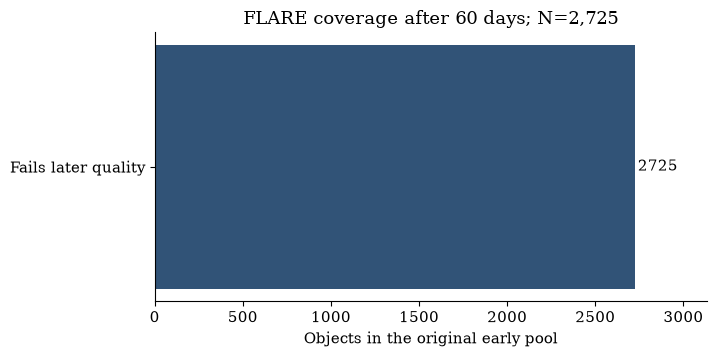

COVERAGE PASS COMPLETE. Inspect this table before switching RUN_MODE to compare.


In [4]:
def clean_detections(aux_doc, alert_docs, cutoff_jd):
    candidates = list(aux_doc.get("prv_candidates", []) or [])
    candidates += [doc.get("candidate", {}) or {} for doc in alert_docs]
    detections = {}
    negative_keys = set()
    rejected = 0
    for candidate in candidates:
        try:
            jd, mag, err = [float(candidate[name]) for name in ("jd", "magpsf", "sigmapsf")]
            fid = int(candidate["fid"])
        except (KeyError, TypeError, ValueError, OverflowError):
            rejected += 1
            continue
        if not np.isfinite([jd, mag, err]).all() or err <= 0 or fid not in (1, 2, 3):
            rejected += 1
            continue
        if jd > cutoff_jd:
            continue
        key = (round(jd, 7), fid)
        detections[key] = (jd - 2400000.5, fid, mag, err)
        if str(candidate.get("issdiffpos", "")).lower() in {"f", "false", "0", "-1"}:
            negative_keys.add(key)
        else:
            negative_keys.discard(key)
    return sorted(detections.values()), len(negative_keys), rejected

def event_summary(rows):
    events = to_events(rows, horizon_days=float(scheme.horizon_days))
    if events is None:
        return events, {"n_events": 0, "n_g": 0, "n_r": 0, "n_i": 0, "quality": False}
    if not np.isfinite(events[:, :8]).all():
        raise RuntimeError("Non-finite FLARE event measurements")
    bands = events[:, flare_data.COL["band_id"]].astype(int)
    return events, {"n_events": len(events), "n_g": int((bands == 0).sum()),
                    "n_r": int((bands == 1).sum()), "n_i": int((bands == 2).sum()),
                    "quality": bool(flare_data.passes_quality(events))}

diagnostic_rows, later_events = [], {}
for entry in early.itertuples(index=False):
    aux = aux_by_object.get(entry.object_id, {})
    alerts = alerts_by_object.get(entry.object_id, [])
    exact = [doc for doc in alerts if str(doc.get("_id")) == entry.candid]
    exact_valid = bool(exact)
    if exact:
        packet = exact[0].get("candidate", {})
        try:
            exact_valid = abs(float(packet["jd"]) - entry.jd) < 1e-6
        except (KeyError, TypeError, ValueError):
            exact_valid = False
    early_rows, _, _ = clean_detections(aux, alerts, float(entry.jd))
    late_rows, negative_n, rejected_n = clean_detections(aux, alerts, float(entry.late_cutoff_jd))
    _, early_summary = event_summary(early_rows)
    events, late_summary = event_summary(late_rows)
    if exact_valid and late_summary["quality"]:
        later_events[entry.object_id] = events
    if not exact_valid:
        outcome = "missing_or_mismatched_acquisition_packet"
    elif not late_rows:
        outcome = "no_usable_photometry"
    elif not late_summary["quality"]:
        outcome = "fails_later_quality"
    elif early_summary["quality"]:
        outcome = "already_eligible"
    else:
        outcome = "became_eligible"
    first_jd = late_rows[0][0] + 2400000.5 if late_rows else np.nan
    diagnostic_rows.append({"object_id": entry.object_id,
        "aux_found": entry.object_id in aux_by_object,
        "triggered_alert_count": len(alerts), "exact_acquisition_packet_valid": exact_valid,
        "n_usable_early": len(early_rows), "n_usable_later": len(late_rows),
        "first_available_detection_jd": first_jd,
        "age_days_at_early_snapshot": entry.jd - first_jd,
        "early_within_native_horizon": bool(np.isfinite(first_jd) and entry.jd - first_jd <= scheme.horizon_days),
        "negative_difference_detections_later": negative_n,
        "invalid_measurement_rows": rejected_n, "outcome": outcome,
        **{"early_" + key: value for key, value in early_summary.items()},
        **{"later_" + key: value for key, value in late_summary.items()}})
coverage = early.merge(pd.DataFrame(diagnostic_rows), on="object_id", validate="one_to_one")
coverage.to_csv(REPORT_DIR / "photometry_coverage.csv", index=False)
counts = coverage.outcome.value_counts().rename_axis("outcome").reset_index(name="objects")
counts["fraction_of_early_pool"] = counts.objects / len(early)
counts.to_csv(REPORT_DIR / "coverage_summary.csv", index=False)
display(counts)
paired_available = len(later_events)
if paired_available < MIN_PAIRED_FOR_SUMMARY:
    warnings.warn(f"Only {paired_available} eligible paired objects. Treat plots as a small pilot; "
                  "this is not a statistically validated sample-size threshold.")
fig, ax = plt.subplots(figsize=(7.3, 3.7))
coverage_labels = {"became_eligible": "Eligible after follow-up", "already_eligible": "Already eligible early",
    "fails_later_quality": "Fails later quality", "no_usable_photometry": "No usable photometry",
    "missing_or_mismatched_acquisition_packet": "Acquisition packet unavailable"}
ax.barh(counts.outcome.map(coverage_labels), counts.objects, color="#315377")
ax.set_xlabel("Objects in the original early pool")
ax.invert_yaxis()
for i, n in enumerate(counts.objects):
    ax.text(n + max(1, len(early) * .006), i, str(n), va="center")
ax.set_xlim(0, max(counts.objects) * 1.15)
ax.set_title(f"FLARE coverage after {FOLLOWUP_DAYS:g} days; N={len(early):,}")
fig.tight_layout()
for extension in ("png", "pdf"):
    fig.savefig(REPORT_DIR / f"followup_coverage.{extension}", dpi=220)
plt.show()
if RUN_MODE == "coverage":
    print("COVERAGE PASS COMPLETE. Inspect this table before switching RUN_MODE to compare.")


## 5. Freeze the full-pool entropy acquisition

In compare mode, the original January `object_inference.npz` is read without changing it. We verify the pool ID, complete object set, alert indices and class dimension. Its accompanying `run_config.json`, if present, must identify `astrominn_vit135` and the expected class order. The new report records its hash and whether model metadata was available; a legacy cache without that metadata is explicitly marked as inherited provenance.

Entropy is calculated through the extracted repository's `EntropyScorer`, which distinguishes logits from probabilities. Top-25 selection happens on the **full early pool**, regardless of later FLARE availability. Ties use object ID for deterministic ordering. Nothing is retrained.

If there is no legacy or local cache, keep `ALLOW_NEW_INFERENCE=False` for the CPU preflight. For a fresh inference pass, set it to true and choose CPU or an allocated GPU. Frozen historical weights and metadata preprocessing use the new repository's existing Delta adapter.


In [5]:
astro = None
inference_provenance = None
if RUN_MODE == "compare":
    local_cache = REPORT_DIR / "early_inference.npz"
    inference_path = local_cache if local_cache.exists() else LEGACY_INFERENCE
    if not inference_path.exists():
        if not ALLOW_NEW_INFERENCE:
            raise FileNotFoundError("No January inference cache. Set LEGACY_INFERENCE correctly, "
                                    "or explicitly enable a new inference pass.")
        from al_pipeline.astronomy.astrominn.inference.run import run_inference
        result = run_inference(model=MODEL_NAME, pool_path=POOL_DIR,
                               device=DEVICE, batch_size=INFERENCE_BATCH_SIZE, num_workers=0)
        np.savez_compressed(local_cache, pool_id=np.asarray(POOL_ID),
            object_ids=np.asarray(result.object_ids, dtype=str),
            alerts=np.asarray(result.alerts, dtype=np.int64),
            values=result.predictions.values, output_type=np.asarray(result.predictions.output_type))
        inference_path = local_cache
    with np.load(inference_path, allow_pickle=False) as payload:
        if str(payload["pool_id"].item()) != POOL_ID:
            raise RuntimeError("Wrong inference cache pool")
        object_ids = payload["object_ids"].astype(str)
        alerts = np.asarray(payload["alerts"], dtype=np.int64)
        predictions = ClassificationPredictions(values=np.asarray(payload["values"]),
                            output_type=str(payload["output_type"].item()))
    if len(object_ids) != len(set(object_ids)) or set(object_ids) != set(early.object_id):
        raise RuntimeError("Inference must cover the complete pool exactly once")
    if len(alerts) != len(object_ids) or predictions.values.shape != (len(object_ids), len(MODEL_CLASSES)):
        raise RuntimeError("Inference arrays or class dimension do not match")
    expected_alerts = early.set_index("object_id").loc[object_ids, "alert"].to_numpy()
    if not np.array_equal(alerts, expected_alerts):
        raise RuntimeError("Inference cache used different early snapshots")
    legacy_config_path = inference_path.parent / "run_config.json"
    legacy_config = json.loads(legacy_config_path.read_text()) if legacy_config_path.exists() else None
    if inference_path == local_cache:
        metadata_status = "generated_by_this_notebook"
    elif legacy_config is None:
        metadata_status = "legacy_model_metadata_unavailable"
        warnings.warn("Legacy predictions have no run_config model metadata; verify their origin before presenting")
    else:
        if legacy_config.get("model") != MODEL_NAME or legacy_config.get("model_class_names") != list(MODEL_CLASSES):
            raise RuntimeError("Legacy model name/class order does not match")
        metadata_status = "legacy_model_metadata_checked"
    p = predictions.as_probabilities()
    astro = pd.DataFrame({"object_id": object_ids, "alert": alerts,
        "astro_entropy": EntropyScorer().score(predictions),
        "astro_predicted_class": np.asarray(MODEL_CLASSES)[p.argmax(axis=1)],
        "astro_max_probability": p.max(axis=1)})
    for j, label in enumerate(MODEL_CLASSES):
        astro["astro_p_" + label] = p[:, j]
    astro = astro.sort_values(["astro_entropy", "object_id"], ascending=[False, True], kind="stable")
    astro["early_entropy_rank"] = np.arange(1, len(astro) + 1)
    astro["selected_early"] = astro.early_entropy_rank <= ACQUISITION_BUDGET
    astro.to_csv(REPORT_DIR / "early_entropy_acquisition.csv", index=False)
    inference_provenance = {"path": str(inference_path), "sha256": sha256(inference_path),
        "metadata_status": metadata_status, "output_type": predictions.output_type,
        "legacy_run_config": legacy_config}
    write_json(REPORT_DIR / "inference_provenance.json", inference_provenance)
    display(astro.head(ACQUISITION_BUDGET)[["object_id", "alert", "astro_entropy", "astro_predicted_class"]])
else:
    print("Coverage mode: AstroMiNN inference and acquisition skipped.")


Coverage mode: AstroMiNN inference and acquisition skipped.


## 6. Later FLARE features and classifier-native energy

All eligible objects are scored, including early nonselections. External host, redshift, Gaia/WISE and positional context columns are explicitly left as NaN. FLARE documents this missing-context path; the report lists exactly which inputs are missing. No current catalog context is introduced into a historical replay.

We call `anomaly_energy` directly. If the clone contains FLARE's dedicated `ad_space` booster, that is the energy model; otherwise FLARE falls back to top-classifier logits and the report names that fallback. Higher energy is ranked first. This is neither FLARE entropy nor an anomaly-label decision.


In [6]:
flare_scores = None
flare_provenance = None
if RUN_MODE == "compare":
    clf = flare.load_classifier(FLARE_SCHEME)
    if not hasattr(clf, "anomaly_energy"):
        raise RuntimeError("Configured FLARE classifier has no anomaly_energy API")
    energy_booster = getattr(clf, "ad_space", None)
    energy_source = "dedicated_ad_space" if energy_booster is not None else "top_classifier_fallback"
    if energy_booster is None:
        energy_booster = clf.top
        warnings.warn("This clone uses top-classifier logits for energy; dedicated ad_space was not loaded")
    required = list(dict.fromkeys(list(clf.feature_names) + list(energy_booster.feature_name())))
    external_cols = set(scheme.external_cols)
    feature_rows = []
    for oid, events in later_events.items():
        features = extract_from_array(events)
        feature_rows.append({"object_id": oid, **features})
    if feature_rows:
        features = pd.DataFrame(feature_rows).set_index("object_id")
        missing_columns = [name for name in required if name not in features]
        unexpected_missing = set(missing_columns) - external_cols
        if unexpected_missing:
            raise RuntimeError("Missing light-curve feature columns: " + str(sorted(unexpected_missing)))
        X = features.reindex(columns=required).replace([np.inf, -np.inf], np.nan)
        energy = np.asarray(clf.anomaly_energy(X), dtype=float)
        labels = np.asarray(clf.predict(X))
        if energy.shape != (len(X),) or not np.isfinite(energy).all():
            raise RuntimeError("FLARE returned invalid energy scores")
        flare_scores = pd.DataFrame({"object_id": X.index,
            "flare_energy": energy, "flare_predicted_class": labels,
            "n_missing_flare_features": X.isna().sum(axis=1).to_numpy()})
        X.to_csv(REPORT_DIR / "later_flare_features.csv", index_label="object_id")
    else:
        missing_columns = required
        flare_scores = pd.DataFrame(columns=["object_id", "flare_energy", "flare_predicted_class",
                                               "n_missing_flare_features"])
    flare_scores.to_csv(REPORT_DIR / "later_flare_scores.csv", index=False)
    flare_provenance = {"scheme": FLARE_SCHEME, "energy_source": energy_source,
        "energy_features": list(energy_booster.feature_name()),
        "classification_features": list(clf.feature_names),
        "external_context_policy": "missing_NaN", "missing_input_columns": missing_columns,
        "model_files": {key: {"path": str(path), "sha256": sha256(path)}
                        for key, path in scheme.model_paths.items() if Path(path).is_file()}}
    write_json(REPORT_DIR / "flare_provenance.json", flare_provenance)
    display(flare_scores.head())
else:
    print("Coverage mode: FLARE classifier scoring skipped.")


Coverage mode: FLARE classifier scoring skipped.


## 7. Paired results, coverage and two distinct overlap questions

**Original acquisition:** of the full-pool top-25 objects, how many can FLARE score later? We keep the original selection and its denominator. Within eligible objects, compare the surviving selection to the same number of highest-energy objects. This is a conditional comparison, not a full-pool FLARE ranking.

**Matched rankings:** on a shared eligible cohort, rerank early entropy and compare its top-k to FLARE's top-k. This is a retrospective ranking diagnostic and must not be presented as the original early acquisition. Report both all later-eligible objects and the subset that became eligible after acquisition.

Spearman correlation uses the entire eligible cohort, including nonselected objects; small or constant-score cohorts do not support a meaningful coefficient. Class predictions are diagnostic annotations, not ground truth, and the two model taxonomies differ.


In [7]:
def correlation_record(frame):
    if len(frame) < 3 or frame.astro_entropy.nunique() < 2 or frame.flare_energy.nunique() < 2:
        return {"n": len(frame), "spearman_rho": None, "spearman_p_value": None}
    result = spearmanr(frame.astro_entropy, frame.flare_energy)
    return {"n": len(frame), "spearman_rho": float(result.statistic),
            "spearman_p_value": float(result.pvalue)}

def overlap_records(frame, cohort_name):
    rows = []
    entropy_order = frame.sort_values(["astro_entropy", "object_id"], ascending=[False, True])
    energy_order = frame.sort_values(["flare_energy", "object_id"], ascending=[False, True])
    # Do not report k=N, where overlap is guaranteed by construction.
    for k in sorted(set([5, 10, ACQUISITION_BUDGET])):
        if k >= len(frame):
            continue
        a, b = set(entropy_order.head(k).object_id), set(energy_order.head(k).object_id)
        common = len(a & b)
        rows.append({"cohort": cohort_name, "cohort_n": len(frame), "k": k,
            "intersection": common, "overlap_fraction": common / k,
            "jaccard": common / len(a | b), "random_expected_overlap_fraction": k / len(frame)})
    return rows

summary = {"mode": RUN_MODE, "pool_id": POOL_ID, "early_pool_objects": len(early),
    "followup_days": FOLLOWUP_DAYS, "later_pairable_objects": paired_available,
    "coverage_outcomes": {str(k): int(v) for k, v in coverage.outcome.value_counts().items()},
    "context_policy": "missing external context", "warnings": []}
paired = None
if RUN_MODE == "compare":
    all_objects = coverage.merge(astro.drop(columns="alert"), on="object_id", validate="one_to_one")
    all_objects = all_objects.merge(flare_scores, on="object_id", how="left", validate="one_to_one")
    all_objects.to_csv(REPORT_DIR / "all_object_results.csv", index=False)
    paired = all_objects.loc[all_objects.flare_energy.notna()].copy()
    paired.to_csv(REPORT_DIR / "paired_objects.csv", index=False)
    cohorts = {"all_later_eligible": paired,
               "became_eligible_later": paired.loc[paired.outcome.eq("became_eligible")]}
    correlations = {name: correlation_record(frame) for name, frame in cohorts.items()}
    overlap = pd.DataFrame([row for name, frame in cohorts.items() for row in overlap_records(frame, name)],
        columns=["cohort", "cohort_n", "k", "intersection", "overlap_fraction", "jaccard",
                 "random_expected_overlap_fraction"])
    overlap.to_csv(REPORT_DIR / "matched_ranking_overlap.csv", index=False)
    selected = paired.loc[paired.selected_early]
    surviving_n = len(selected)
    energy_selected = set(paired.sort_values(["flare_energy", "object_id"], ascending=[False, True])
                                  .head(surviving_n).object_id)
    surviving_ids = set(selected.object_id)
    common = len(surviving_ids & energy_selected)
    original_overlap = {"original_budget": ACQUISITION_BUDGET,
        "selected_scoreable_later": surviving_n, "eligible_comparison_universe": len(paired),
        "selected_followup_coverage": surviving_n / ACQUISITION_BUDGET,
        "intersection_with_energy_top_surviving_n": common,
        "conditional_overlap_fraction": common / surviving_n if surviving_n else None,
        "full_budget_intersection_fraction": common / ACQUISITION_BUDGET,
        "ranking_trivial": bool(surviving_n and surviving_n == len(paired))}
    selected_coverage = all_objects.loc[all_objects.selected_early, "outcome"].value_counts()
    summary.update({"correlations": correlations, "original_acquisition": original_overlap,
        "selected_coverage_outcomes": {str(k): int(v) for k, v in selected_coverage.items()},
        "energy_source": flare_provenance["energy_source"],
        "inference_metadata_status": inference_provenance["metadata_status"]})
    if len(paired) < MIN_PAIRED_FOR_SUMMARY:
        summary["warnings"].append("Small paired cohort; descriptive pilot only")
    if surviving_n == 0:
        summary["warnings"].append("No original entropy-selected objects could be scored by FLARE later")
    if original_overlap["ranking_trivial"]:
        summary["warnings"].append("Surviving selection spans the eligible universe; original-selection overlap is trivial")
    if inference_provenance["metadata_status"] == "legacy_model_metadata_unavailable":
        summary["warnings"].append("Legacy model metadata unavailable; provenance requires verification")
    display(pd.DataFrame(correlations).T)
    display(pd.DataFrame([original_overlap]))
    display(overlap)
write_json(REPORT_DIR / "comparison_summary.json", summary)


## 8. Presentation figures

The main figure puts early entropy on the horizontal axis and later energy on the vertical axis. Gray points are early nonselections; blue circles are early selections that became eligible later; blue squares are early selections FLARE could already score. A hollow black circle identifies newly eligible nonselections. Every plotted point is one object.

Coverage stays visible beside the comparison. A second panel separates already-eligible from newly eligible objects; a third shows matched-cohort ranking overlap when enough objects are available. All figures are exported as PNG and PDF. The notebook still completes and reports coverage if zero objects are pairable.


In [8]:
def plot_pairs(ax, frame, title):
    for selected_flag, outcome, marker, face, edge, label in [
        (False, "already_eligible", "s", "#bbbbbb", "#bbbbbb", "Nonselected; already eligible"),
        (False, "became_eligible", "o", "none", "#777777", "Nonselected; eligible later"),
        (True, "already_eligible", "s", "#315377", "#315377", "Selected; already eligible"),
        (True, "became_eligible", "o", "#315377", "#315377", "Selected; eligible later"),
    ]:
        subset = frame.loc[frame.selected_early.eq(selected_flag) & frame.outcome.eq(outcome)]
        if len(subset):
            ax.scatter(subset.astro_entropy, subset.flare_energy, s=35 if not selected_flag else 70,
                marker=marker, facecolors=face, edgecolors=edge, linewidths=.8,
                alpha=.75 if not selected_flag else 1., label=label, zorder=3 if selected_flag else 2)
    ax.set_xlabel("Early AstroMiNN entropy [nats]")
    ax.set_ylabel("Later FLARE anomaly energy")
    ax.set_title(title)
    record = correlation_record(frame)
    rho_text = "undefined" if record["spearman_rho"] is None else f'{record["spearman_rho"]:.2f}'
    ax.text(.03, .97, f'N = {len(frame)}; Spearman rho = {rho_text}',
            transform=ax.transAxes, va="top", fontsize=10,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": .95, "pad": 3})
    if len(frame):
        ax.legend(loc="best", fontsize=8)

if RUN_MODE == "compare":
    if len(paired):
        fig, ax = plt.subplots(figsize=(8.0, 4.7))
        plot_pairs(ax, paired, f"Early uncertainty → energy after {FOLLOWUP_DAYS:g} days")
        fig.text(.5, -.025,
            f'Original top-{ACQUISITION_BUDGET}: {len(selected)}/{ACQUISITION_BUDGET} scoreable later '
            f'| FLARE bts6; external context missing', ha="center", fontsize=9)
        fig.tight_layout()
        for extension in ("png", "pdf"):
            fig.savefig(REPORT_DIR / f"early_entropy_later_energy.{extension}", dpi=240)
        plt.show()
        fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), sharey=True)
        plot_pairs(axes[0], paired.loc[paired.outcome.eq("already_eligible")], "Already eligible at the early snapshot")
        plot_pairs(axes[1], paired.loc[paired.outcome.eq("became_eligible")], "Became eligible during follow-up")
        fig.tight_layout()
        for extension in ("png", "pdf"):
            fig.savefig(REPORT_DIR / f"eligibility_cohort_comparison.{extension}", dpi=220)
        plt.show()
    else:
        print("No pairable objects: coverage plot is the appropriate result.")
    if len(overlap):
        fig, ax = plt.subplots(figsize=(7.2, 3.8))
        for name, group in overlap.groupby("cohort", sort=False):
            ax.plot(group.k, group.overlap_fraction, marker="o", label=name.replace("_", " "))
            ax.plot(group.k, group.random_expected_overlap_fraction, linestyle=":", color="#999999",
                    label="Random expectation (" + name.replace("_", " ") + ")")
        ax.set(xlabel="Top-k within the same eligible cohort", ylabel="Intersection / k", ylim=(0, 1.05))
        ax.legend(fontsize=8)
        fig.tight_layout()
        for extension in ("png", "pdf"):
            fig.savefig(REPORT_DIR / f"matched_ranking_overlap.{extension}", dpi=220)
        plt.show()


## 9. Concrete examples and review bundle

The table below supplies objects for an optional slide example. It uses within-cohort ranks to find agreement and disagreement; it does not assign confirmed astrophysical labels. Each row retains the early candid/JD, alert index, band counts, follow-up cutoff, predictions and both scores. The complete CSV contains all paired objects.

The review archive contains only the modest report products—not large raw photometry, images, model weights or credentials. Raw compressed query caches remain on Delta, with their locations and hashes in `raw_cache_receipts.json`. Rerunning compare mode uses the same cached photometry. Save the executed notebook separately, or copy it into `REPORT_DIR` before rerunning this cell if you want it included in the archive.


In [9]:
if RUN_MODE == "compare" and len(paired):
    example_table = paired.copy()
    n = len(example_table)
    example_table["entropy_rank_fraction"] = example_table.astro_entropy.rank(ascending=False, method="average") / n
    example_table["energy_rank_fraction"] = example_table.flare_energy.rank(ascending=False, method="average") / n
    example_table["rank_gap"] = example_table.energy_rank_fraction - example_table.entropy_rank_fraction
    examples = []
    seen = set()
    for description, frame in [
        ("Original entropy selection, strongest later energy", example_table.loc[example_table.selected_early]
            .sort_values("flare_energy", ascending=False)),
        ("High early uncertainty relative to later anomaly rank", example_table.sort_values("rank_gap", ascending=False)),
        ("High later anomaly rank relative to early uncertainty", example_table.sort_values("rank_gap")),
    ]:
        for _, row in frame.iterrows():
            if row.object_id not in seen:
                examples.append({"example": description, **row.to_dict()})
                seen.add(row.object_id)
                break
    examples = pd.DataFrame(examples)
    examples.to_csv(REPORT_DIR / "example_objects.csv", index=False)
    display(examples[["example", "object_id", "outcome", "selected_early", "astro_entropy", "flare_energy",
                      "early_n_events", "later_n_events", "later_n_g", "later_n_r"]])

readme = f'''# {RUN_ID}
Mode: {RUN_MODE}. Original early pool: {len(early)} objects.
Follow-up cutoff: each saved early snapshot JD + {FOLLOWUP_DAYS:g} days.
FLARE: {FLARE_SCHEME}; native first-{scheme.horizon_days:g}-day window from first available detection.
External FLARE context is missing (NaN); this is a photometry-only/missing-context comparison.
Original pool query was capped; no claim of complete January coverage.
Inspect comparison_summary.json, coverage_summary.csv and photometry_coverage.csv first.
Full raw photometry stays on Delta; see raw_cache_receipts.json for locations/hashes.
Confirmed labels were not queried. Neither prediction nor energy establishes an astrophysical class.
Matched ranking overlap reranks within eligible cohorts; it is distinct from original AL selection.
'''
(REPORT_DIR / "README.txt").write_text(readme)
archive_path = REPORT_DIR.parent / (RUN_ID + "_" + RUN_MODE + "_review.tar.gz")
with tarfile.open(archive_path, "w:gz") as archive:
    coverage_products = {"early_snapshots.csv", "run_config.json", "raw_cache_receipts.json",
        "photometry_coverage.csv", "coverage_summary.csv", "comparison_summary.json", "README.txt",
        "followup_coverage.png", "followup_coverage.pdf"}
    for path in sorted(REPORT_DIR.iterdir()):
        if path.is_file() and path.suffix in {".csv", ".json", ".txt", ".png", ".pdf", ".ipynb"}:
            if RUN_MODE == "coverage" and path.name not in coverage_products and path.suffix != ".ipynb":
                continue
            archive.add(path, arcname=RUN_ID + "/" + path.name)
print("Review archive:", archive_path)
print(json.dumps(summary, indent=2))


Review archive: /projects/bcrv/dkourtesis/applecider_adaptive/reports/early_astrominn_later_flare_january_v1_coverage_review.tar.gz
{
  "mode": "coverage",
  "pool_id": "boom_ztf_2025_january_early10_v1",
  "early_pool_objects": 2725,
  "followup_days": 60.0,
  "later_pairable_objects": 0,
  "coverage_outcomes": {
    "fails_later_quality": 2725
  },
  "context_policy": "missing external context",
  "warnings": []
}


## Suggested slide after we inspect the real output

**Title:** Early uncertainty and later anomaly ranking

- Main figure: `early_entropy_later_energy.pdf` (or the newly-eligible panel if that cohort is sufficiently populated).
- Small statistics: paired object count; original top-25 follow-up coverage; conditional overlap or Spearman rho when meaningful.
- Footnote: fixed 60-day follow-up; FLARE native quality gate; external context missing; one point per object.
- Interpretation should follow the results: agreement, complementary rankings, or insufficient follow-up coverage. Do not promise a correlation or usable anomaly-label yield before the run.

**Implementation sources:** new `al_pipeline.core.scoring.entropy`, `al_pipeline.astronomy.boom.client`, and `al_pipeline.astronomy.astrominn.inference.run`; existing January acquisition notebook 10; FLARE `fetch.to_events`, `data.passes_quality`, `features.extract_from_array`, `hierarchical.HierarchicalFlare.anomaly_energy`. FLARE API inspection for this notebook used repository commit `e95a86360f25f860ea275d33546e34dd40ca5d6a`; runtime provenance records your actual clone and model hashes.
